<a href="https://colab.research.google.com/github/antonioguizar-collab/Actividad3BDManipulacion/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.impute import SimpleImputer

# 1 y 2. Descargar archivo y guardar en dataframe estableciendo 'id' como índice
cardio_df = pd.read_csv('heart_disease.csv', index_col='id')

# 3. Utiliza el método info() del dataframe
print("--- Información del DataFrame y tipos de datos ---")
cardio_df.info()

# 4. Determina la cantidad de valores únicos por columna
print("\n--- Cantidad de valores únicos por columna ---")
print(cardio_df.nunique())

--- Información del DataFrame y tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB

--- Cantidad de valores únicos por columna ---
age          50
sex           2
origin        4
cp            4
trestbps  

In [2]:
# Inspeccionar variables numéricas con pocos valores únicos
print("Valores únicos antes de la conversión:")
print(cardio_df[['ca', 'num']].nunique())

# Convertir a categóricas. 'num' y 'ca' son ordinales
cardio_df['ca'] = cardio_df['ca'].astype('category')
cardio_df['num'] = cardio_df['num'].astype('category')

print("\nTipos de datos actualizados:")
print(cardio_df[['ca', 'num']].dtypes)

Valores únicos antes de la conversión:
ca     4
num    5
dtype: int64

Tipos de datos actualizados:
ca     category
num    category
dtype: object


In [3]:
# Estadísticas descriptivas para variables numéricas (incluyendo sesgo y curtosis)
num_cols = cardio_df.select_dtypes(include=[np.number]).columns
stats_num = cardio_df[num_cols].describe().T
stats_num['sesgo (skew)'] = cardio_df[num_cols].skew()
stats_num['curtosis (kurt)'] = cardio_df[num_cols].kurt()

print("--- Estadísticas de Variables Numéricas ---")
display(stats_num) # Usamos display para que se vea como tabla bonita en Colab

# Estadísticas para variables categóricas (Tablas de frecuencia)
print("\n--- Tablas de Frecuencia de Variables Categóricas ---")
cat_cols = cardio_df.select_dtypes(exclude=[np.number]).columns
for col in cat_cols:
    print(f"\nFrecuencias de '{col}':")
    print(cardio_df[col].value_counts(dropna=False))

--- Estadísticas de Variables Numéricas ---


,count,mean,std,min,25%,50%,75%,max,sesgo (skew),curtosis (kurt)
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834



--- Tablas de Frecuencia de Variables Categóricas ---

Frecuencias de 'sex':
sex
Male      724
Female    194
Name: count, dtype: int64

Frecuencias de 'origin':
origin
Cleveland        304
Hungary          292
VA Long Beach    200
Switzerland      122
Name: count, dtype: int64

Frecuencias de 'cp':
cp
asymptomatic       495
non-anginal        204
atypical angina    174
typical angina      45
Name: count, dtype: int64

Frecuencias de 'fbs':
fbs
False    691
True     138
NaN       89
Name: count, dtype: int64

Frecuencias de 'restecg':
restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
Name: count, dtype: int64

Frecuencias de 'exang':
exang
False    526
True     337
NaN       55
Name: count, dtype: int64

Frecuencias de 'slope':
slope
flat           345
NaN            308
upsloping      202
downsloping     63
Name: count, dtype: int64

Frecuencias de 'ca':
ca
NaN     609
 0.0    181
 1.0     67
 2.0     41
 3.0     20
Name: count, dtype: int64

Frecuencias 

--- Porcentaje de valores faltantes ---
age          0.000000
sex          0.000000
origin       0.000000
cp           0.000000
trestbps     6.427015
chol         3.267974
fbs          9.694989
restecg      0.000000
thalch       5.991285
exang        5.991285
oldpeak      6.753813
slope       33.551198
ca          66.339869
thal        52.723312
num          0.000000
dtype: float64

Columnas eliminadas (>30% faltantes): ['slope', 'ca', 'thal']


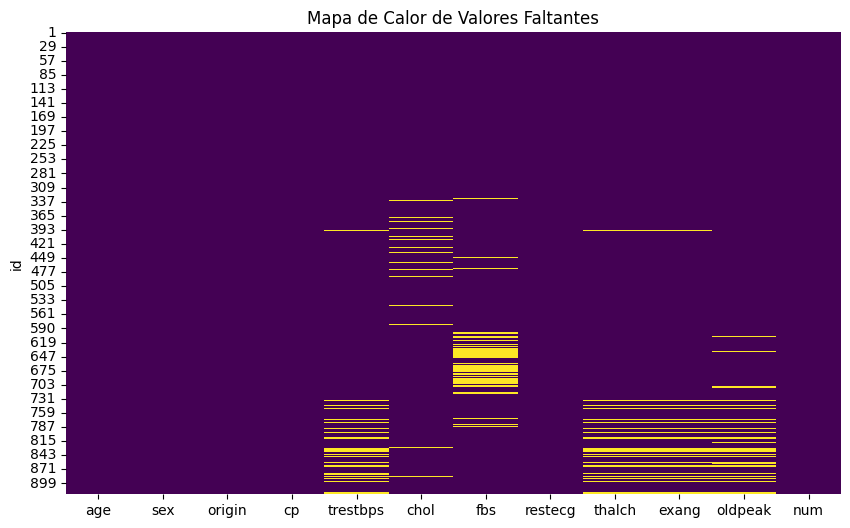

In [4]:
# 7. Calcula el porcentaje de valores faltantes en cada columna
missing_pct = (cardio_df.isnull().sum() / len(cardio_df)) * 100
print("--- Porcentaje de valores faltantes ---")
print(missing_pct)

# 8. Elimina aquellas columnas cuyo porcentaje supere el 30%
cols_to_drop = missing_pct[missing_pct > 30].index.tolist()
cardio_df.drop(columns=cols_to_drop, inplace=True)
print(f"\nColumnas eliminadas (>30% faltantes): {cols_to_drop}")

# 9. Crea un mapa de calor que visualice la distribución
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor de Valores Faltantes')
plt.show()

In [5]:
# Dividir cada columna en dos grupos: con / sin faltantes en thalch
missing_thalch = cardio_df['thalch'].isnull()
grupo_con_faltantes = cardio_df[missing_thalch]
grupo_sin_faltantes = cardio_df[~missing_thalch]

print("--- Pruebas de Hipótesis para thalch ---")

# Para numéricas: Age y Chol (Prueba t de Student)
t_stat_age, p_age = ttest_ind(grupo_con_faltantes['age'].dropna(), grupo_sin_faltantes['age'].dropna())
print(f"P-value para Age: {p_age:.5f}")

t_stat_chol, p_chol = ttest_ind(grupo_con_faltantes['chol'].dropna(), grupo_sin_faltantes['chol'].dropna())
print(f"P-value para Chol: {p_chol:.5f}")

# Para categóricas: restecg y cp (Prueba Chi-cuadrada)
contingency_restecg = pd.crosstab(missing_thalch, cardio_df['restecg'])
chi2_r, p_restecg, dof_r, ex_r = chi2_contingency(contingency_restecg)
print(f"P-value para Restecg: {p_restecg:.5f}")

contingency_cp = pd.crosstab(missing_thalch, cardio_df['cp'])
chi2_c, p_cp, dof_c, ex_c = chi2_contingency(contingency_cp)
print(f"P-value para CP: {p_cp:.5f}")

--- Pruebas de Hipótesis para thalch ---
P-value para Age: 0.00000
P-value para Chol: 0.71653
P-value para Restecg: 0.00000
P-value para CP: 0.15420


/tmp/ipykernel_2793/3303404265.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(x.mode()[0]))


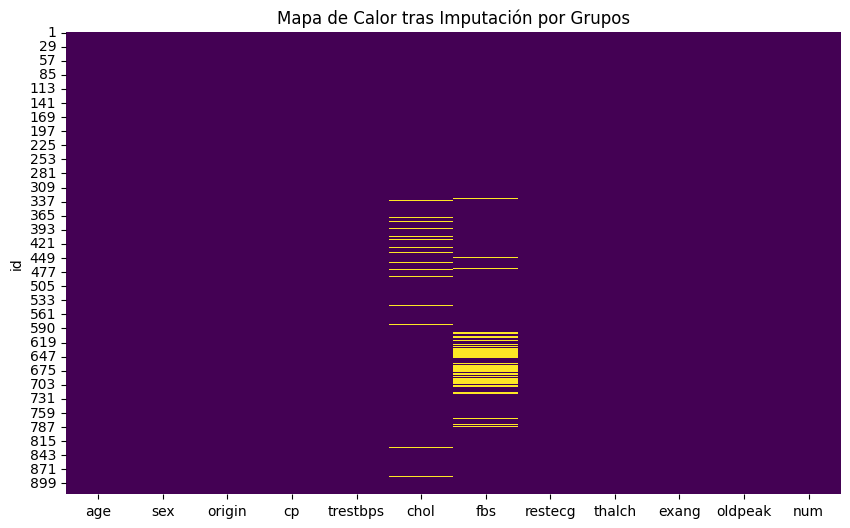

In [6]:
# 12. Imputar usando la variable restecg para separar los grupos
# Para numéricas: usamos transform con median()
cols_num_miss = ['thalch', 'oldpeak', 'trestbps']
for col in cols_num_miss:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))

# Para la variable categórica exang: usamos la moda (mode()[0])
cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(x.mode()[0]))

# 13. Vuelve a generar el mapa de calor
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor tras Imputación por Grupos')
plt.show()

In [9]:
from sklearn.impute import SimpleImputer

# 14. Imputación general sin segmentar por grupos usando SimpleImputer
# Para numéricas (ej. chol) usamos la mediana
imputer_num = SimpleImputer(strategy='median')
cardio_df['chol'] = imputer_num.fit_transform(cardio_df[['chol']]).ravel()

# Para categóricas (ej. fbs) usamos most_frequent
imputer_cat = SimpleImputer(strategy='most_frequent')
cardio_df['fbs'] = imputer_cat.fit_transform(cardio_df[['fbs']]).ravel()

print("Total de valores nulos tras todas las imputaciones:")
print(cardio_df.isnull().sum())

Total de valores nulos tras todas las imputaciones:
age         0
sex         0
origin      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
dtype: int64


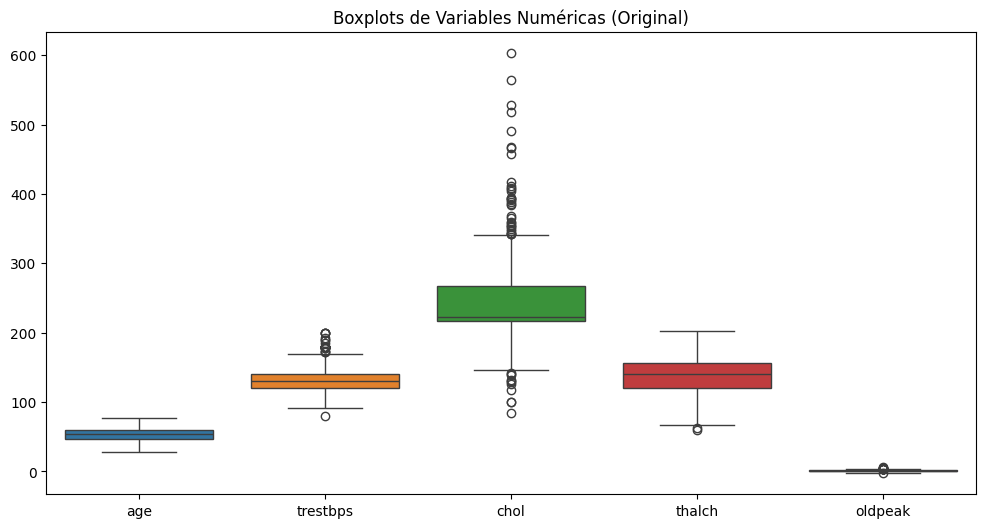

Límite inferior para trestbps: 90.0
Límite superior para trestbps: 170.0


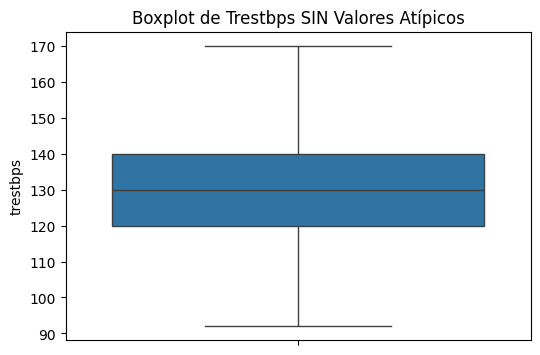

In [8]:
# 15. Dibuja boxplots de todas las variables numéricas
num_cols = cardio_df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(12, 6))
sns.boxplot(data=cardio_df[num_cols])
plt.title('Boxplots de Variables Numéricas (Original)')
plt.show()

# 16. Calcula los valores atípicos de trestbps (IQR)
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

print(f"Límite inferior para trestbps: {limite_inf}")
print(f"Límite superior para trestbps: {limite_sup}")

# 17. Elimina los valores atípicos identificados
cardio_df_clean = cardio_df[(cardio_df['trestbps'] >= limite_inf) & (cardio_df['trestbps'] <= limite_sup)]

# 18. Dibuja el boxplot final para visualizar la distribución depurada
plt.figure(figsize=(6, 4))
sns.boxplot(y=cardio_df_clean['trestbps'])
plt.title('Boxplot de Trestbps SIN Valores Atípicos')
plt.show()